# MicroCT step 1c — warm start and positions

Takes `code.npy` and `prb.npy` from **this folder's own stage 0** (`<root>/nfp`,
written by `step0.py`) and works out where the strong CA sat during scan 94,
then writes the last three datasets `step6.py` needs.

Two conventions matter most, both inherited from
`BoneNano_coded_holotomo/step3_find_shifts.ipynb` -- read that file if
anything here is unclear, it has the full reasoning after several rounds of
fixes:

- **Stage 0's grid origin is arbitrary.** It anchored its aperture plane to
  scan 93's own grid, which says nothing about scan 94. So positions here are
  measured *directly against a reference built from stage 0's own output* --
  stage 0 chains between its own frames, this stage does not.
- **The sign is negated**, matching every phascade experiment on this engine
  family.

`pos_obj` is **zero** here: the sample is fixed in scan 94 (only the strong CA
moves), and there is no rotation axis to offset.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('../../src'))
import numpy as np, cupy as cp, h5py
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

def cbshow(ax, img, title, cmap='gray', **kw):
    im = ax.imshow(np.asarray(img), cmap=cmap, **kw)
    ax.set_title(title, fontsize=9)
    cax = make_axes_locatable(ax).append_axes('right', size='5%', pad=0.05)
    ax.figure.colorbar(im, cax=cax)

print('GPU:', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())

GPU: NVIDIA A100-SXM4-40GB


## Config

In [2]:
# --- everything comes from config_step6.conf. Edit THAT file, not this cell.
from holotomocupy.config import parse_args_holo_coded
CFG = parse_args_holo_coded('config_step6.conf')

RAW_DIR = '/data3/cekmekci/microCT_nano_holo'   # raw_dir; parse_args_holo_coded has no key for it
OUT_H5  = CFG.in_file

DARK_H5   = f'{RAW_DIR}/scan-0090_orca.h5'   # dark
FLAT_H5   = f'{RAW_DIR}/scan-0091_orca.h5'   # flat: NO CA at all
WEAKCA_H5 = f'{RAW_DIR}/scan-0092_orca.h5'   # weak CA alone, no sample -> pref
GRID_H5   = f'{RAW_DIR}/scan-0094_orca.h5'   # weak + strong CA + SAMPLE (fixed), 121 frames
ORCA      = '/entry/instrument/orca/data'

ENERGY  = CFG.energy if CFG.energy is not None else 19.90
Z1      = CFG.z1                 # focus -> SAMPLE (TODO CONFIRM, see config comment)
Z_CODE  = CFG.z1_code            # focus -> weak/strong CA plane
Z_DET   = CFG.focusdetectordistance
DET_PIX = CFG.detector_pixelsize # UNBINNED
nz, n   = CFG.crop_nz, CFG.crop_n   # NATIVE crop resolution -- NOT CFG.nz/CFG.n,
                                    # which are the solve's own BINNED grid.
                                    # Steps 1a-1c never bin anything; that is
                                    # HoloCodedReader's job alone at solve time.
CROP = (nz, n)
DEZINGER = (3, 0.8)
NFRAMES = CFG.nframes   # ALL 121 frames of scan 94 -- no subsampling anywhere

print(f'{ENERGY} keV   z1(sample) {Z1} m   z1_code(CA plane) {Z_CODE} m   z_det {Z_DET} m')
print(f'crop {CROP}, native resolution -- the solve bins to {CFG.nz} x {CFG.n} at bin={CFG.bin}')
assert Z_CODE < Z1, 'the CA plane must be BEFORE the sample for RecHoloCoded'

19.9 keV   z1(sample) 0.14925 m   z1_code(CA plane) 0.14125 m   z_det 0.74625 m
crop (2048, 2048), native resolution -- the solve bins to 512 x 512 at bin=2


## Geometry

In [3]:
with h5py.File(GRID_H5, 'r') as f:
    NANG, NY, NX = f[ORCA].shape
assert NANG == NFRAMES, f'{GRID_H5} has {NANG} frames, config says nframes={NFRAMES}'
cy, cx = NY // 2, NX // 2
SL = (slice(cy - CROP[0] // 2, cy + CROP[0] // 2),
      slice(cx - CROP[1] // 2, cx + CROP[1] // 2))

mag       = Z_DET / Z1
voxelsize = DET_PIX / mag   # NATIVE voxel size -- no bin factor, steps 1a-1c never bin

print(f'orca {NY} x {NX}, {NANG} frames; crop rows {SL[0].start}:{SL[0].stop} '
      f'cols {SL[1].start}:{SL[1].stop}')
print(f'voxel {voxelsize*1e9:.2f} nm   magnification {mag:.3f}')

orca 2592 x 4608, 121 frames; crop rows 272:2320 cols 1280:3328
voxel 46.00 nm   magnification 5.000


## The warm start from stage 0

Stage 0 ran on the same native crop, also unbinned (`bin=0` in
`config_step0.conf`) -- steps 1a-1c never bin anything, so the stage-0 arrays
are reused as-is, only cropped in case the two configs' planes ever differ.

In [4]:
from holotomocupy.propagation import Propagation

code_nfp = np.load(CFG.code_file).astype('complex64')
prb_nfp  = np.load(CFG.code_file.replace('code.npy', 'prb.npy')).astype('complex64')
print('code.npy', code_nfp.shape, '  prb.npy', prb_nfp.shape)

def crop_center(a, my, mx):
    ky, kx = a.shape
    sy, sx = (ky - my) // 2, (kx - mx) // 2
    return a[sy:sy + my, sx:sx + mx]

code_c = crop_center(code_nfp, n, n).astype('complex64')
prb_c  = crop_center(prb_nfp,  n, n).astype('complex64')
print(f'central {n}x{n} taken for the reference (native resolution, no bin)')

code.npy (4096, 4096)   prb.npy (2048, 2048)
central 2048x2048 taken for the reference (native resolution, no bin)


## Build the reference speckle

Push stage 0's code and probe through the same forward chain the data went
through, then apply the same two divisions. What comes out is what the
strong CA *should* look like on the detector, which is what the frames get
registered against.

d1 (CA->sample) +8.4531 mm   d2 (sample->det) +119.4000 mm


/home/beams0/CEKMEKCI/Desktop/holotomocupy/src/holotomocupy/propagation.py:44: UserWarning: nvcc not found (NVCC='nvcc'). Set NVCC env var or add nvcc to PATH. Falling back to cuPy FFT.
  self._use_cufftdx = cufftdx_available()


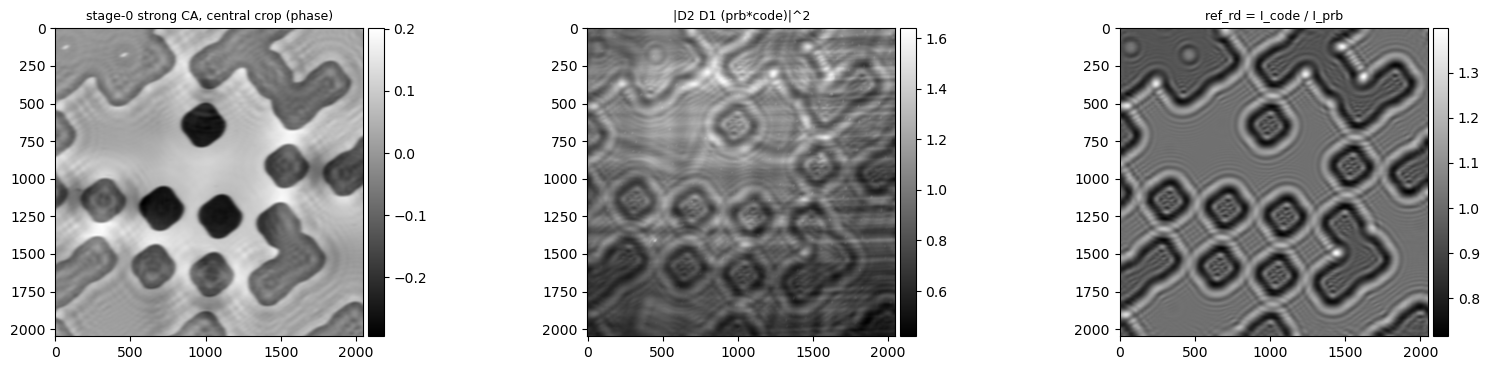

In [5]:
# RecHoloCoded computes d1/d2 internally from z1/z1_code/fdd; replicate that
# here so the reference is built on the geometry the solver will actually use.
z2  = Z_DET - Z1
distance = Z1 * z2 / Z_DET
z2c = Z1 - Z_CODE
distance_code = (Z_CODE * z2c) / (Z_CODE + z2c)
norm_mag_code = (Z1 / Z_CODE) / (Z_CODE / Z1)
distance_code = distance_code * norm_mag_code ** 2 * (Z_CODE / Z1) ** 2
print(f'd1 (CA->sample) {distance_code*1e3:+.4f} mm   '
      f'd2 (sample->det) {distance*1e3:+.4f} mm')

wavelength = 1.24e-9 / ENERGY
P1 = Propagation(n, nz, 1, 1, wavelength, voxelsize, np.array([distance_code]))
P2 = Propagation(n, nz, 1, 1, wavelength, voxelsize, np.array([distance]))

g_prb, g_code = cp.asarray(prb_c), cp.asarray(code_c)
I_prb  = cp.abs(P2.D(P1.D(g_prb[None], 0), 0)[0]) ** 2
I_code = cp.abs(P2.D(P1.D((g_prb * g_code)[None], 0), 0)[0]) ** 2
ref_rd = I_code / (I_prb + 1e-6)   # kept on GPU

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
cbshow(ax[0], np.angle(code_c), 'stage-0 strong CA, central crop (phase)')
cbshow(ax[1], cp.asnumpy(I_code), '|D2 D1 (prb*code)|^2')
cbshow(ax[2], cp.asnumpy(ref_rd), 'ref_rd = I_code / I_prb')
plt.tight_layout(); plt.show()

In [6]:
def phase_corr(a, b):
    A, B = cp.fft.fft2(cp.asarray(a)), cp.fft.fft2(cp.asarray(b))
    cc = cp.fft.fftshift(cp.fft.ifft2(A * cp.conj(B)).real)
    i = cp.unravel_index(cp.argmax(cc), cc.shape)
    return (np.array([int(i[0]) - cc.shape[0] // 2,
                      int(i[1]) - cc.shape[1] // 2], 'float32'),
            float(cc.max() / (cc.std() + 1e-8)))

## Diagnostic: did the probe move between stage 0 and this scan?

The weak CA is supposed to have stayed put since scan 92. The strong CA's
walk averages out of scan 94's theta-mean, leaving beam + weak CA + the
(fixed) sample. Compare that against the stage-0 probe pushed through the
same forward model -- not a formality, see `BoneNano_nfp/README.md`'s
"CA1 moved between scan 69 and scan 80" section for what an unmeasured drift
cost there.

probe shift (stage0 -> scan94): row 0.00  col 0.00 px
||diff|| before = 1.715e+02   after = 1.715e+02
  -> negligible, consistent with reusing the stage-0 probe unmodified.


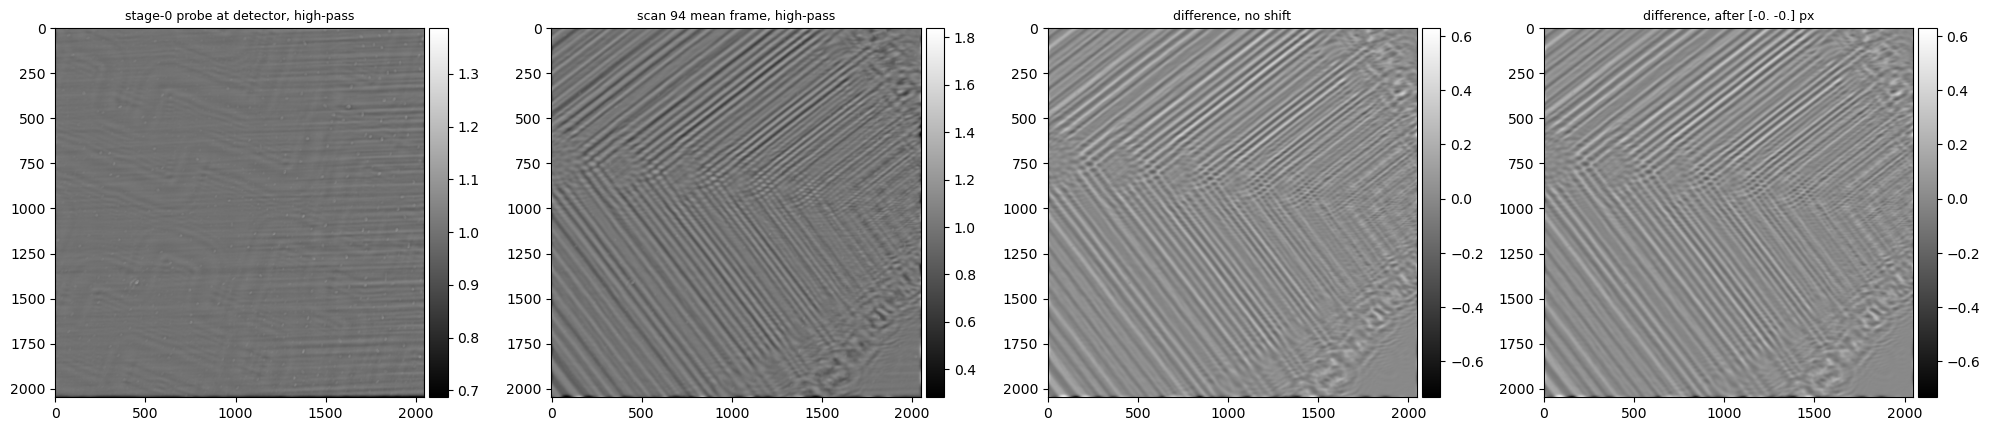

In [7]:
CHUNK = 16
with h5py.File(OUT_H5, 'r') as f:
    static_sum = np.zeros((nz, n), 'float64')
    for cs in range(0, NFRAMES, CHUNK):
        ce = min(cs + CHUNK, NFRAMES)
        static_sum += np.asarray(f['/exchange/pdata'][cs:ce], 'float32').sum(0, dtype='float64')
static = cp.asarray((static_sum / NFRAMES).astype('float32'))

def hp(img, s=0.02):
    f = cp.fft.fftfreq(img.shape[0]).astype('float32')
    fx, fy = cp.meshgrid(f, f)
    lp = cp.exp(-(fx ** 2 + fy ** 2) / (2 * s ** 2)).astype('float32')
    return (img / (cp.fft.ifft2(cp.fft.fft2(img) * lp).real + 1e-3)).astype('float32')

I_prb_hp, static_hp = hp(I_prb), hp(static)
prb_shift, _ = phase_corr(I_prb_hp, static_hp)
rolled = cp.roll(I_prb_hp, (-int(round(prb_shift[0])), -int(round(prb_shift[1]))), axis=(0, 1))
print(f'probe shift (stage0 -> scan94): row {prb_shift[0]:.2f}  col {prb_shift[1]:.2f} px')
print(f'||diff|| before = {float(cp.linalg.norm(I_prb_hp - static_hp)):.3e}   '
      f'after = {float(cp.linalg.norm(rolled - static_hp)):.3e}')
if abs(prb_shift[0]) >= 1 or abs(prb_shift[1]) >= 1:
    print('  -> NON-NEGLIGIBLE. See BoneNano_nfp/README.md for what that cost there.')
else:
    print('  -> negligible, consistent with reusing the stage-0 probe unmodified.')

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
cbshow(ax[0], cp.asnumpy(I_prb_hp), 'stage-0 probe at detector, high-pass')
cbshow(ax[1], cp.asnumpy(static_hp), 'scan 94 mean frame, high-pass')
cbshow(ax[2], cp.asnumpy(I_prb_hp - static_hp), 'difference, no shift')
cbshow(ax[3], cp.asnumpy(rolled - static_hp), f'difference, after {-prb_shift} px')
plt.tight_layout(); plt.show()

## Positions

Isolate the strong CA with the two divisions, then correlate every frame
against the reference. `pos_obj` is zero -- the sample is fixed in scan 94.

Watch the **confidence** trace. A frame where the peak is not far above the
background is a frame whose position is a guess.

pass 1/2: theta-mean of pdata/pref over all 121 frames
  pass 2/2: 0/121
  pass 2/2: 20/121
  pass 2/2: 40/121
  pass 2/2: 60/121
  pass 2/2: 80/121
  pass 2/2: 100/121
  pass 2/2: 120/121
offset to stage 0 = [-18.  -1.] px
walk span         = [1001. 1007.] px
confidence  median 2883.3  min 2477.8 (frame 27)


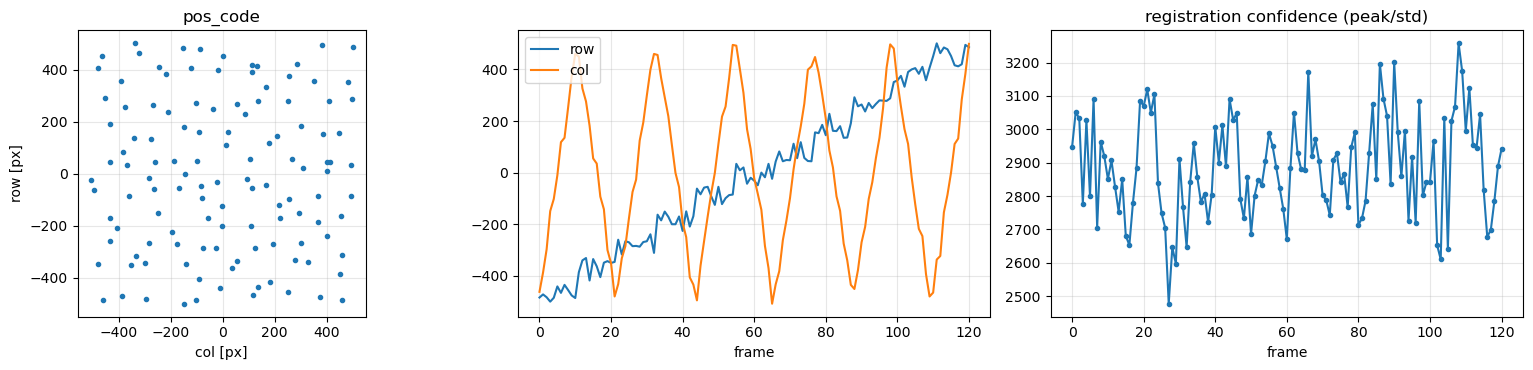

In [8]:
CHUNK = 16
with h5py.File(OUT_H5, 'r') as f:
    pref = np.asarray(f['/exchange/pref'], 'float32')
    rd_sum = np.zeros((nz, n), 'float64')
    for cs in range(0, NFRAMES, CHUNK):
        ce = min(cs + CHUNK, NFRAMES)
        chunk = np.asarray(f['/exchange/pdata'][cs:ce], 'float32') / (pref[None] + 1e-6)
        rd_sum += chunk.sum(0, dtype='float64')
rd_mean = (rd_sum / NFRAMES).astype('float32')
print(f'pass 1/2: theta-mean of pdata/pref over all {NFRAMES} frames')

pref_gpu    = cp.asarray(pref)
rd_mean_gpu = cp.asarray(rd_mean) + 1e-6
res = []
stepk = np.empty((NFRAMES - 1, 2), 'float32')
prev_rd = None
with h5py.File(OUT_H5, 'r') as f:
    pdata_dset = f['/exchange/pdata']
    for k in range(NFRAMES):
        rd_k = cp.asarray(pdata_dset[k], 'float32') / (pref_gpu + 1e-6) / rd_mean_gpu
        res.append(phase_corr(ref_rd, rd_k))
        if prev_rd is not None:
            stepk[k - 1] = phase_corr(prev_rd, rd_k)[0]
        prev_rd = rd_k
        if k % 20 == 0:
            print(f'  pass 2/2: {k}/{NFRAMES}', flush=True)

# NEGATED, and registered DIRECTLY against ref_rd rather than chained.
pos_code = -np.stack([r[0] for r in res]).astype('float32')
conf = np.array([r[1] for r in res], 'float32')

pos_obj = np.zeros((NFRAMES, 2), 'float32')   # the sample is FIXED in scan 94

print(f'offset to stage 0 = {np.round(np.median(pos_code, 0), 2)} px')
print(f'walk span         = {np.round(np.ptp(pos_code, 0), 1)} px')
print(f'confidence  median {np.median(conf):.1f}  min {conf.min():.1f} '
      f'(frame {int(conf.argmin())})')

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(pos_code[:, 1], pos_code[:, 0], 'o', ms=3)
ax[0].set_xlabel('col [px]'); ax[0].set_ylabel('row [px]'); ax[0].set_aspect('equal')
ax[0].set_title('pos_code'); ax[0].grid(alpha=.3)
ax[1].plot(pos_code[:, 0], label='row'); ax[1].plot(pos_code[:, 1], label='col')
ax[1].set_xlabel('frame'); ax[1].legend(); ax[1].grid(alpha=.3)
ax[2].plot(conf, '.-'); ax[2].set_xlabel('frame')
ax[2].set_title('registration confidence (peak/std)'); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

## Diagnostic: does an independent chain registration agree?

Consecutive-frame cross-correlation, cumulative from a mid-scan anchor,
exactly as stage 0 does it. It never touches stage 0's code, so agreement
with the absolute positions above is evidence the registration is actually
correct, not just self-consistent.

|absolute - chain|: median [ 7. 18.] px   95th pct [32. 43.] px
  healthy: ~1 px. Much larger means the absolute registration above is not actually locking onto the strong CA.


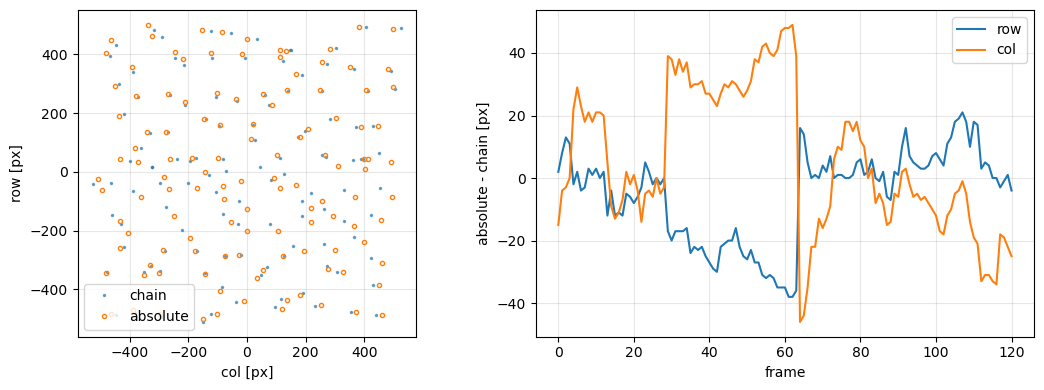

In [9]:
ipos = NFRAMES // 2
chain = np.zeros((NFRAMES, 2), 'float32')
for k in range(ipos):
    chain[k] = np.sum(stepk[k:ipos], axis=0)
for k in range(ipos + 1, NFRAMES):
    chain[k] = -np.sum(stepk[ipos:k], axis=0)
chain = chain + np.median(pos_code - chain, axis=0)
resid = pos_code - chain

print(f'|absolute - chain|: median {np.round(np.median(np.abs(resid), 0), 2)} px   '
      f'95th pct {np.round(np.percentile(np.abs(resid), 95, 0), 2)} px')
print('  healthy: ~1 px. Much larger means the absolute registration above is '
      'not actually locking onto the strong CA.')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(chain[:, 1], chain[:, 0], '.', ms=3, alpha=0.6, label='chain')
ax[0].plot(pos_code[:, 1], pos_code[:, 0], 'o', ms=3, mfc='none', label='absolute')
ax[0].set_xlabel('col [px]'); ax[0].set_ylabel('row [px]'); ax[0].grid(alpha=.3)
ax[0].set_aspect('equal'); ax[0].legend()
ax[1].plot(resid[:, 0], label='row'); ax[1].plot(resid[:, 1], label='col')
ax[1].set_xlabel('frame'); ax[1].set_ylabel('absolute - chain [px]'); ax[1].grid(alpha=.3); ax[1].legend()
plt.tight_layout(); plt.show()

## Diagnostic: is the configured canvas big enough?

`ncode` must clear `n + 2*max|pos_code| + 2*EX + 32`, or the per-frame code
window reads past the edge of the plane. Same for `nobj`. Everything in
NATIVE px -- this stage runs unbinned throughout.

In [12]:
EX = 16 * 2 ** CFG.bin   # same physical margin as the holotomo folder, scaled
                         # from 16 BINNED px up to native px for this bin

import numpy as _np
_code_on_disk = _np.load(CFG.code_file, mmap_mode='r').shape[0]
ncode_at_bin = _code_on_disk >> CFG.bin
print(f'stage-0 code.npy is {_code_on_disk} px, NATIVE -- the solve will bin it '
      f'by 2**{CFG.bin} -> {ncode_at_bin}')
print(f'   config ncode = {CFG.ncode}' +
      ('   OK' if CFG.ncode == ncode_at_bin else
       f'   MISMATCH -- set ncode={ncode_at_bin} or re-run stage 0 with a different npsi'))

nobj_native = CFG.nobj << CFG.bin
need_code = n + 2 * int(np.ceil(np.abs(pos_code).max())) + 2 * EX + 32
need_obj  = n + 2 * int(np.ceil(np.abs(pos_obj).max()))  + 2 * EX + 32
print()
print(f'walk needs code plane >= {need_code} native px   '
      f'(stage-0 npsi is {_code_on_disk})')
print(f'walk needs nobj       >= {need_obj} native px    '
      f'(config nobj={CFG.nobj} at bin={CFG.bin} is {nobj_native} native px)')
if _code_on_disk < need_code:
    print('  -> stage 0 npsi is TOO SMALL for the walk measured here. Raise '
          'npsi in config_step0.conf and re-run stage 0.')
if nobj_native < need_obj:
    print(f'  -> raise nobj in config_step6.conf to at least '
          f'{int(np.ceil(need_obj / 2 ** CFG.bin / 32) * 32)} (at bin={CFG.bin})')
if _code_on_disk >= need_code and nobj_native >= need_obj:
    print('  -> grids are large enough')

stage-0 code.npy is 4096 px, NATIVE -- the solve will bin it by 2**2 -> 1024
   config ncode = 2048   MISMATCH -- set ncode=1024 or re-run stage 0 with a different npsi

walk needs code plane >= 3224 native px   (stage-0 npsi is 4096)
walk needs nobj       >= 2208 native px    (config nobj=640 at bin=2 is 2560 native px)
  -> grids are large enough


## Write to `codedHolo.h5`

In [13]:
with h5py.File(OUT_H5, 'a') as f:
    for k, v in (('shifts_code', pos_code),
                 ('shifts_cor',  pos_obj)):
        if f'/exchange/{k}' in f:
            del f[f'/exchange/{k}']
        f.create_dataset(f'/exchange/{k}', data=v.astype('float32'))
    if '/exchange/prb' in f:
        del f['/exchange/prb']
    f.create_dataset('/exchange/prb', data=prb_nfp.astype('complex64'))
print('wrote /exchange/{shifts_code, shifts_cor, prb} (native, unbinned px)')
print()
print('codedHolo.h5 now has everything step6.py needs:')
with h5py.File(OUT_H5, 'r') as f:
    for k in sorted(f['/exchange']):
        print(f'   /exchange/{k:24s} {f["/exchange"][k].shape}')
print()
print('Next:  mpirun -np <ngpus> ./set_affinity_gpu.sh python step6.py config_step6.conf')

wrote /exchange/{shifts_code, shifts_cor, prb} (native, unbinned px)

codedHolo.h5 now has everything step6.py needs:
   /exchange/dark                     (2048, 2048)
   /exchange/dead_mask                (2048, 2048)
   /exchange/detector_pixelsize       (1,)
   /exchange/energy                   (1,)
   /exchange/flat_mean                (1,)
   /exchange/flat_norm                (2048, 2048)
   /exchange/focusdetectordistance    (1,)
   /exchange/pdata                    (121, 2048, 2048)
   /exchange/prb                      (2048, 2048)
   /exchange/pref                     (2048, 2048)
   /exchange/shifts_code              (121, 2)
   /exchange/shifts_cor               (121, 2)
   /exchange/voxelsize                (1,)
   /exchange/z1                       (1,)

Next:  mpirun -np <ngpus> ./set_affinity_gpu.sh python step6.py config_step6.conf
